<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
00. Graph Neural Networks for Molecular Representation Using DeepChem
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Representing Molecules as Mathematical Graphs, Extracting Atom-Bond Tensors, and Batching for Geometric Deep Learning</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h3 style="margin-top: 0; color: #1e1b4b; font-size: 18px; font-weight: 700;">
Objective
</h3>
<p style="font-size: 14px; color: #334155; margin-bottom: 16px;">
Learn how to represent molecules as graphs and prepare molecular graph features for graph neural network (GNN) models.
</p>

<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">
Learning Objectives
</h4>
<p style="font-size: 13.5px; color: #334155; margin-bottom: 8px;">By the end of this notebook, you will be able to:</p>
<ol style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7; margin-bottom: 16px;">
<li>Explain molecular graphs and their chemical meaning.</li>
<li>Convert SMILES strings into molecular graph representations.</li>
<li>Extract atom and bond features using DeepChem.</li>
<li>Inspect graph nodes, edges, and feature matrices.</li>
<li>Visualize molecular connectivity.</li>
<li>Compare molecular graphs with circular fingerprints.</li>
<li>Understand message passing and graph convolution.</li>
<li>Prepare molecular graph datasets for downstream prediction tasks.</li>
</ol>

<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">
Applications in AI Drug Discovery
</h4>
<div style="display: grid; grid-template-columns: repeat(auto-fit, minmax(220px, 1fr)); gap: 12px; margin-top: 8px;">
<div style="background: #ffffff; border: 1px solid #c7d2fe; border-radius: 8px; padding: 12px;">
<div style="font-weight: 700; color: #4338ca; font-size: 13px;">Molecular Property Prediction</div>
<div style="font-size: 12px; color: #64748b; margin-top: 2px;">Solubility, lipophilicity, permeability.</div>
</div>
<div style="background: #ffffff; border: 1px solid #c7d2fe; border-radius: 8px; padding: 12px;">
<div style="font-weight: 700; color: #4338ca; font-size: 13px;">QSAR Modeling</div>
<div style="font-size: 12px; color: #64748b; margin-top: 2px;">Bioactivity and potency estimation.</div>
</div>
<div style="background: #ffffff; border: 1px solid #c7d2fe; border-radius: 8px; padding: 12px;">
<div style="font-weight: 700; color: #4338ca; font-size: 13px;">Toxicity Prediction</div>
<div style="font-size: 12px; color: #64748b; margin-top: 2px;">Nuclear receptor, stress pathway disruption.</div>
</div>
<div style="background: #ffffff; border: 1px solid #c7d2fe; border-radius: 8px; padding: 12px;">
<div style="font-weight: 700; color: #4338ca; font-size: 13px;">Drug–Target Interactions</div>
<div style="font-size: 12px; color: #64748b; margin-top: 2px;">Enzyme and receptor binding affinity.</div>
</div>
</div>
</div>


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
01. Introduction to Molecular Graphs & Graph Theory Fundamentals
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Mathematical Formulation of Atoms as Nodes, Bonds as Edges, and Chemical Feature Tensors</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
The Molecular Graph Formulation: G = (V, E)
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
In chemical graph theory, a molecule is represented as an attributed graph $G = (V, E)$:
</p>
<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7;">
<li><b>Node Set $V$ (Atoms):</b> Each atom $v \in V$ is represented by a feature vector $\mathbf{x}_v \in \mathbb{R}^{d_v}$ encoding physicochemical attributes: atomic number, formal charge, hybridization state ($sp, sp^2, sp^3$), aromaticity, implicit hydrogen count, and chirality.</li>
<li><b>Edge Set $E$ (Chemical Bonds):</b> Each chemical bond $(u, v) \in E$ is represented by an edge feature vector $\mathbf{e}_{uv} \in \mathbb{R}^{d_e}$ capturing bond type (single, double, triple, aromatic), conjugation, and stereochemical configuration $(E/Z)$.</li>
<li><b>Connectivity / Adjacency:</b> Represented either by an adjacency matrix $\mathbf{A} \in \{0, 1\}^{|V| 	imes |V|}$ or an <code>edge_index</code> tensor of shape $(2, |E|)$ defining directed pairs of connected atoms.</li>
</ul>
<p style="font-size: 13.5px; color: #475569; margin: 0;">
Unlike circular fingerprints (which compress local neighborhoods into fixed-length bit vectors), graph representations preserve the <b>exact, uncompressed spatial and topological connectivity</b> of the chemical system.
</p>
</div>


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
02. Environment Setup, Silent Imports & Reproducibility
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Initializing DeepChem, RDKit, NetworkX, and Locking Global Random Seeds</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<p style="font-size: 14px; color: #334155; margin: 0;">
We initialize DeepChem, RDKit, NetworkX, and core scientific computing libraries with low-level C++ descriptor redirection to ensure spotless notebook outputs and reproducible graph featurization.
</p>
</div>


In [1]:
# 1. Environment and Logging Configuration
import os
import sys
import io
import logging
import warnings
import random

# Suppress TensorFlow C++ logging and oneDNN diagnostics
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore")
logging.getLogger("tensorflow").setLevel(logging.ERROR)
logging.getLogger("deepchem").setLevel(logging.ERROR)

# Suppress RDKit C++ deprecation warnings (e.g., MorganGenerator notices)
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

# 2. Quiet Import of DeepChem suppressing low-level C and stream stderr
old_stderr = sys.stderr
sys.stderr = io.StringIO()
devnull = os.open(os.devnull, os.O_WRONLY)
old_stderr_fd = os.dup(2)
try:
    os.dup2(devnull, 2)
    import tensorflow as tf
    tf.get_logger().setLevel("ERROR")
    import deepchem as dc
    from deepchem.feat import MolGraphConvFeaturizer, ConvMolFeaturizer, CircularFingerprint
    from deepchem.feat.mol_graphs import ConvMol
finally:
    os.dup2(old_stderr_fd, 2)
    os.close(devnull)
    os.close(old_stderr_fd)
    sys.stderr = old_stderr

# 3. Core Scientific, Cheminformatics, and Graph Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

import rdkit
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors

# 4. Set Global Seeds for Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Visual Styling Setup
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "semibold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14,
    "figure.titleweight": "bold"
})

print(f"DeepChem Version : {dc.__version__}")
print(f"RDKit Version    : {rdkit.__version__}")
print(f"NetworkX Version : {nx.__version__}")
print(f"Pandas Version   : {pd.__version__}")
print(f"NumPy Version    : {np.__version__}")
print(f"Random Seed      : {RANDOM_SEED} (Locked for Reproducibility)")


DeepChem Version : 2.8.1.dev
RDKit Version    : 2026.09.1
NetworkX Version : 3.6.1
Pandas Version   : 3.0.6
NumPy Version    : 2.3.5
Random Seed      : 42 (Locked for Reproducibility)


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
03. SMILES to Molecular Graph (RDKit Foundation)
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Parsing Representative Chemotypes Across Size, Ring Topologies, and Heteroatoms</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Representative Molecular Chemotypes
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
To thoroughly explore molecular graph structures, we examine four molecules representing diverse structural motifs:
</p>
<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7;">
<li><b>Ethanol (<code>CCO</code>):</b> Minimal linear aliphatic alcohol (3 heavy atoms, simple chain topology).</li>
<li><b>Benzene (<code>c1ccccc1</code>):</b> Monocyclic conjugated aromatic ring (6 carbon atoms, delocalized $\pi$-electrons).</li>
<li><b>Aspirin (<code>CC(=O)Oc1ccccc1C(=O)O</code>):</b> Drug molecule containing both an aromatic core and aliphatic ester/carboxylic branches.</li>
<li><b>Caffeine (<code>Cn1c(=O)c2c(ncn2C)n(C)c1=O</code>):</b> Fused bicyclic purine heterocycle enriched in nitrogen heteroatoms and carbonyl groups.</li>
</ul>
</div>


In [2]:
# Create example molecular dataset
molecules = pd.DataFrame({
    "name": ["Ethanol", "Benzene", "Aspirin", "Caffeine"],
    "smiles": [
        "CCO",
        "c1ccccc1",
        "CC(=O)Oc1ccccc1C(=O)O",
        "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
    ],
})

# Convert SMILES to RDKit Mol objects
molecules["mol"] = molecules["smiles"].apply(Chem.MolFromSmiles)
molecules["heavy_atoms"] = molecules["mol"].apply(lambda m: m.GetNumHeavyAtoms())
molecules["num_bonds"] = molecules["mol"].apply(lambda m: m.GetNumBonds())
molecules["mol_weight"] = molecules["mol"].apply(lambda m: round(Descriptors.MolWt(m), 2))

print("=" * 70)
print("REPRESENTATIVE MOLECULAR COHORT")
print("=" * 70)
display(molecules[["name", "smiles", "heavy_atoms", "num_bonds", "mol_weight"]])


REPRESENTATIVE MOLECULAR COHORT


,name,smiles,heavy_atoms,num_bonds,mol_weight
0,Ethanol,CCO,3,2,46.07
1,Benzene,c1ccccc1,6,6,78.11
2,Aspirin,CC(=O)Oc1ccccc1C(=O)O,13,13,180.16
3,Caffeine,Cn1c(=O)c2c(ncn2C)n(C)c1=O,14,15,194.19


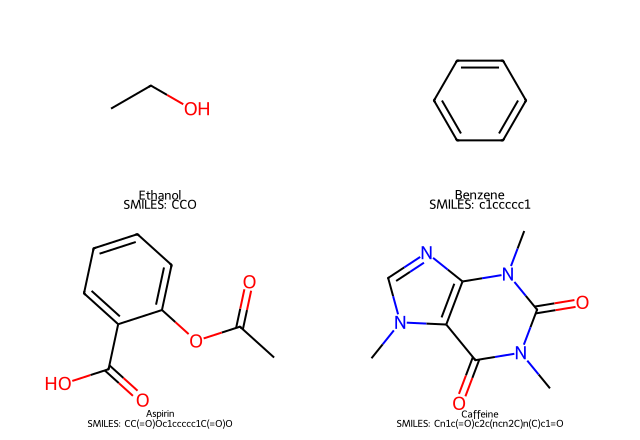

In [3]:
# Visualize 2D chemical structures of the representative cohort
img = Draw.MolsToGridImage(
    molecules["mol"].tolist(),
    legends=[f"{name}\nSMILES: {smi}" for name, smi in zip(molecules["name"], molecules["smiles"])],
    molsPerRow=2,
    subImgSize=(320, 220),
)
display(img)


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
04. DeepChem Graph Featurizers
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Architectural Comparison: MolGraphConvFeaturizer vs. ConvMolFeaturizer</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Two Core Graph Representations in DeepChem
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
DeepChem offers two primary graph featurizers tailored for different downstream neural network architectures:
</p>
<div style="overflow-x: auto; margin-bottom: 16px;">
<table style="width: 100%; border-collapse: collapse; font-size: 13.5px;">
<thead>
<tr style="background: #eef2ff; color: #1e1b4b; text-align: left; border-bottom: 2px solid #c7d2fe;">
<th style="padding: 10px 14px; font-weight: 700;">Featurizer</th>
<th style="padding: 10px 14px; font-weight: 700;">Output Data Type</th>
<th style="padding: 10px 14px; font-weight: 700;">Node Feature Dim</th>
<th style="padding: 10px 14px; font-weight: 700;">Edge Handling</th>
<th style="padding: 10px 14px; font-weight: 700;">Target GNN Architectures</th>
</tr>
</thead>
<tbody>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 10px 14px; font-weight: 600; color: #4338ca;"><code>MolGraphConvFeaturizer</code></td>
<td style="padding: 10px 14px; color: #334155;"><code>GraphData</code> (PyG/DGL compatible)</td>
<td style="padding: 10px 14px; color: #475569;">30 or 32 dimensions</td>
<td style="padding: 10px 14px; color: #334155;"><code>edge_index</code> $(2, E)$ + 11-dim edge features</td>
<td style="padding: 10px 14px; color: #334155;">GCN, GAT, MPNN, SchNet, PyTorch Geometric models.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0; background: #fafbff;">
<td style="padding: 10px 14px; font-weight: 600; color: #4338ca;"><code>ConvMolFeaturizer</code></td>
<td style="padding: 10px 14px; color: #334155;"><code>ConvMol</code> (DeepChem native)</td>
<td style="padding: 10px 14px; color: #475569;">75 dimensions</td>
<td style="padding: 10px 14px; color: #334155;">Adjacency lists grouped by atom degree</td>
<td style="padding: 10px 14px; color: #334155;">DeepChem's classic <code>GraphConvModel</code>.</td>
</tr>
</tbody>
</table>
</div>
</div>


In [4]:
# 1. Initialize MolGraphConvFeaturizer with edge features and chirality
mg_featurizer = MolGraphConvFeaturizer(
    use_edges=True,
    use_chirality=True,
)

# Featurize the cohort
graphs = mg_featurizer.featurize(molecules["smiles"].tolist())

# 2. Initialize ConvMolFeaturizer
cm_featurizer = ConvMolFeaturizer()
conv_mols = cm_featurizer.featurize(molecules["smiles"].tolist())

print("=" * 70)
print("FEATURIZATION SUMMARY ACROSS MOLECULES")
print("=" * 70)
summary_records = []
for name, g, cm in zip(molecules["name"], graphs, conv_mols):
    summary_records.append({
        "Molecule": name,
        "GraphData Nodes": g.num_nodes,
        "GraphData Node Features": str(g.node_features.shape),
        "GraphData Directed Edges": g.edge_index.shape[1],
        "GraphData Edge Features": str(g.edge_features.shape),
        "ConvMol Atom Features": str(cm.atom_features.shape)
    })

display(pd.DataFrame(summary_records).set_index("Molecule"))


FEATURIZATION SUMMARY ACROSS MOLECULES


,GraphData Nodes,GraphData Node Features,GraphData Directed Edges,GraphData Edge Features,ConvMol Atom Features
Molecule,,,,,
Ethanol,3,"(3, 32)",4,"(4, 11)","(3, 75)"
Benzene,6,"(6, 32)",12,"(12, 11)","(6, 75)"
Aspirin,13,"(13, 32)",26,"(26, 11)","(13, 75)"
Caffeine,14,"(14, 32)",30,"(30, 11)","(14, 75)"


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
05. Deep Inspection of Graph Representations
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Dissecting Node Feature Matrices, Edge Indices, and Bond Attributes for Ethanol</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Chemical Interpretation of the Ethanol Graph
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
Examining the simplest molecule, <b>Ethanol (<code>CCO</code>)</b>, reveals key principles of molecular graph construction:
</p>
<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7;">
<li><b><code>num_nodes = 3</code>:</b> The graph contains 3 heavy-atom nodes (2 carbons, 1 oxygen). Hydrogens are treated <i>implicitly</i> by default to conserve computational bandwidth, with hydrogen counts embedded as node attributes.</li>
<li><b><code>node_features.shape = (3, 32)</code>:</b> Each of the 3 atoms is encoded as a 32-dimensional vector describing atomic identity, hybridization, formal charge, and aromaticity.</li>
<li><b><code>edge_index.shape = (2, 4)</code>:</b> Graph neural networks operate on <i>directed</i> edges. A single chemical bond between atom $u$ and atom $v$ is represented as two opposing directed edges ($u 	o v$ and $v 	o u$). Therefore, Ethanol's 2 single bonds yield $2 	imes 2 = 4$ directed edges.</li>
<li><b><code>edge_features.shape = (4, 11)</code>:</b> Each directed edge carries an 11-dimensional feature vector encoding bond order, conjugation, and ring membership.</li>
</ul>
</div>


In [5]:
# Extract and inspect the Ethanol GraphData object
ethanol_graph = graphs[0]

print("=" * 70)
print("ETHANOL (CCO) GRAPH DATA STRUCTURE")
print("=" * 70)
print("Number of nodes (heavy atoms) :", ethanol_graph.num_nodes)
print("Node features tensor shape    :", ethanol_graph.node_features.shape)
print("Edge index tensor shape       :", ethanol_graph.edge_index.shape)
print("Edge features tensor shape    :", ethanol_graph.edge_features.shape)
print("-" * 70)

# Display the directed edge connectivity pairs
print("Directed Edge Index Pairs (Source -> Target):")
for i in range(ethanol_graph.edge_index.shape[1]):
    src = ethanol_graph.edge_index[0, i]
    dst = ethanol_graph.edge_index[1, i]
    print(f"  Edge {i}: Node {src} -> Node {dst}")

print("-" * 70)
print("Node Features Matrix (First 10 of 32 dimensions for each atom):")
df_node_preview = pd.DataFrame(
    ethanol_graph.node_features[:, :10],
    index=["Atom 0 (C)", "Atom 1 (C)", "Atom 2 (O)"],
    columns=[f"Feat_{k}" for k in range(10)]
)
display(df_node_preview)


ETHANOL (CCO) GRAPH DATA STRUCTURE
Number of nodes (heavy atoms) : 3
Node features tensor shape    : (3, 32)
Edge index tensor shape       : (2, 4)
Edge features tensor shape    : (4, 11)
----------------------------------------------------------------------
Directed Edge Index Pairs (Source -> Target):
  Edge 0: Node 0 -> Node 2
  Edge 1: Node 2 -> Node 0
  Edge 2: Node 2 -> Node 1
  Edge 3: Node 1 -> Node 2
----------------------------------------------------------------------
Node Features Matrix (First 10 of 32 dimensions for each atom):


,Feat_0,Feat_1,Feat_2,Feat_3,Feat_4,Feat_5,Feat_6,Feat_7,Feat_8,Feat_9
Atom 0 (C),1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Atom 1 (C),0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Atom 2 (O),1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
06. Visualizing Molecular Graph Topologies
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Explicit Mathematical Graph Plots with Atom Color-Coding and Bond Multiplicities</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Bridging Visual Chemistry and Graph Networks
</h4>
<p style="font-size: 14px; color: #334155; margin: 0;">
To make abstract graph tensors concrete, we convert our RDKit molecules into <code>NetworkX</code> graph objects and render their topological layouts. Each node is labeled with its atom symbol and color-coded by elemental identity, while edges represent covalent bonds.
</p>
</div>


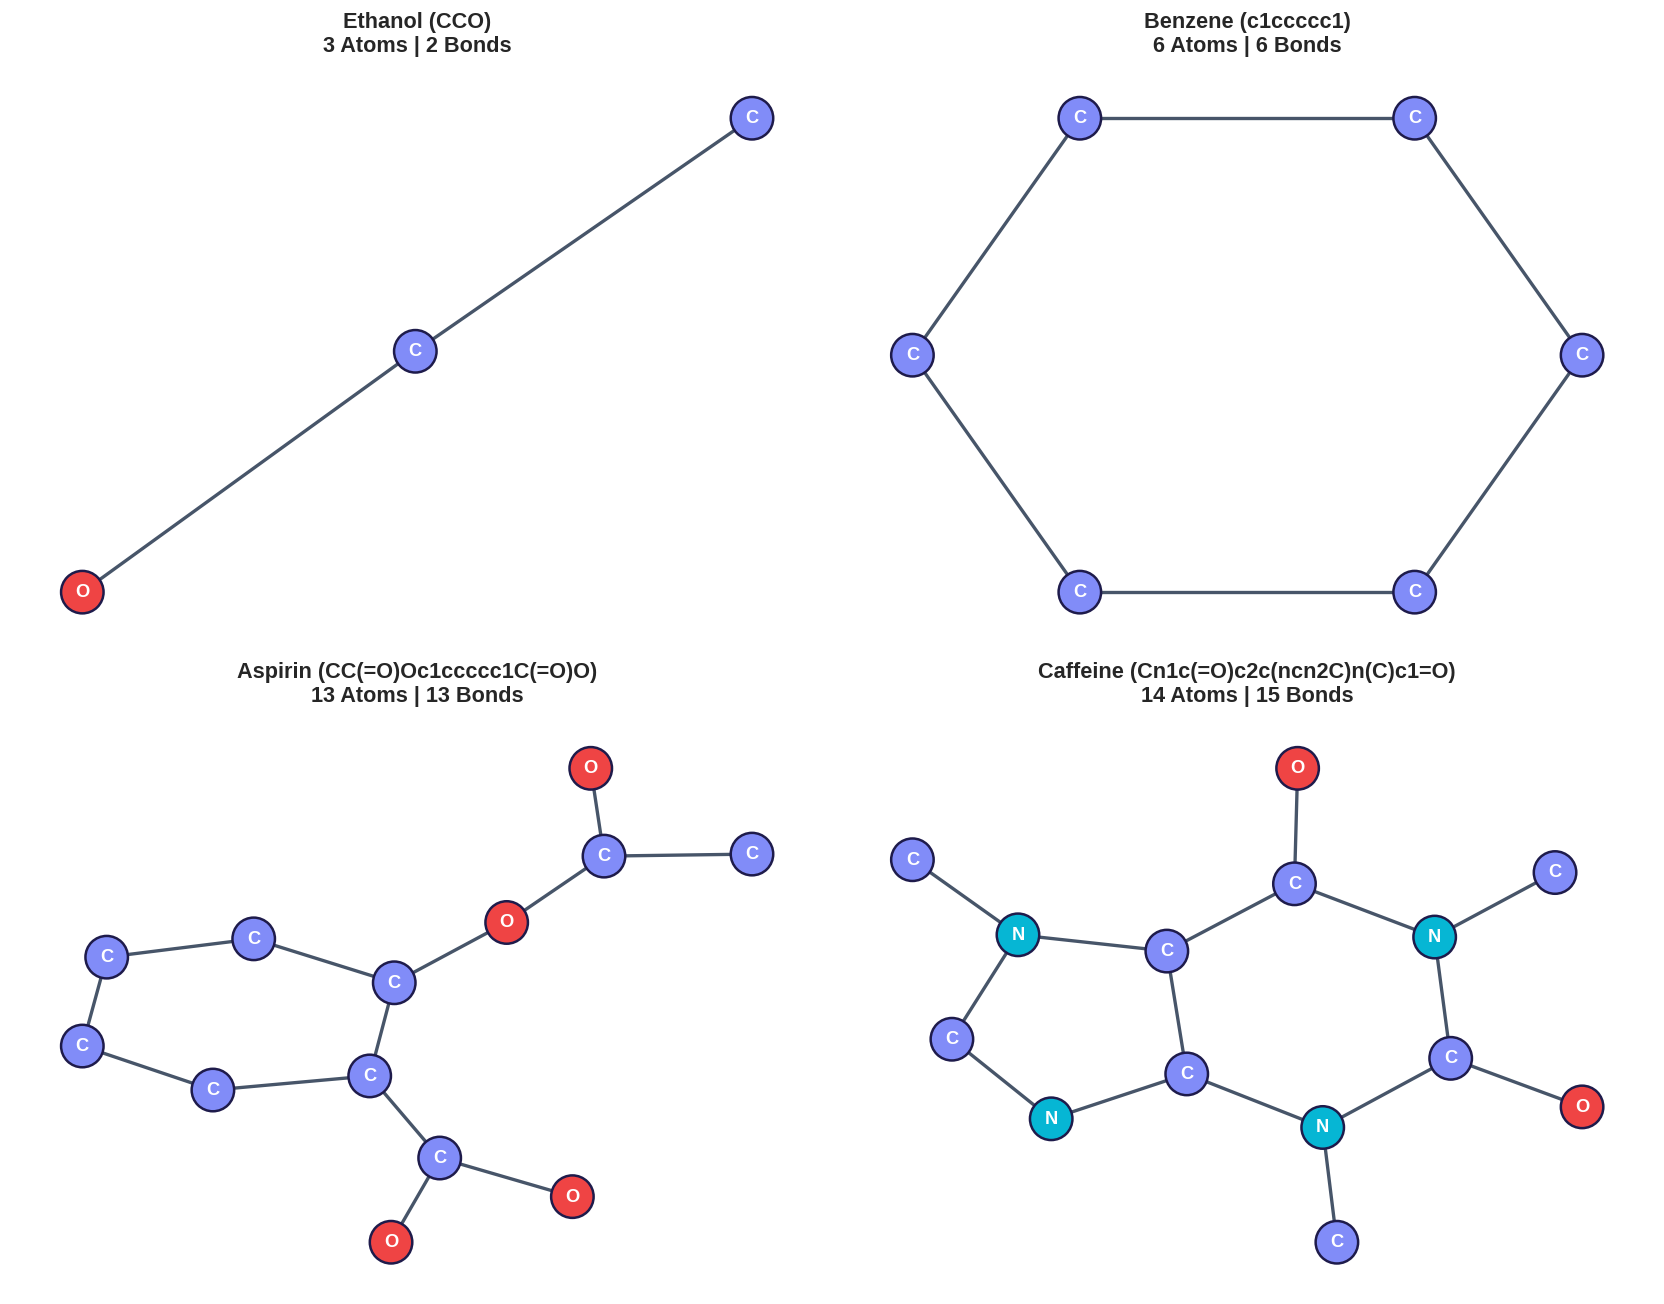

In [6]:
# Visualize molecular graphs using NetworkX and Matplotlib
fig, axes = plt.subplots(2, 2, figsize=(14, 11), dpi=120)
axes = axes.flatten()

# Element color palette
element_colors = {
    "C": "#818cf8",   # Indigo / Carbon
    "O": "#ef4444",   # Red / Oxygen
    "N": "#06b6d4",   # Cyan / Nitrogen
    "H": "#f8fafc",   # White / Hydrogen
}

for i, (_, row) in enumerate(molecules.iterrows()):
    mol = row["mol"]
    name = row["name"]
    
    # Construct NetworkX Graph
    G = nx.Graph()
    for atom in mol.GetAtoms():
        G.add_node(
            atom.GetIdx(),
            symbol=atom.GetSymbol(),
            atomic_num=atom.GetAtomicNum()
        )
    for bond in mol.GetBonds():
        G.add_edge(
            bond.GetBeginAtomIdx(),
            bond.GetEndAtomIdx(),
            order=bond.GetBondTypeAsDouble()
        )
    
    # Layout using Kamada-Kawai or spring
    pos = nx.kamada_kawai_layout(G)
    
    # Extract node attributes
    node_symbols = nx.get_node_attributes(G, "symbol")
    node_colors = [element_colors.get(node_symbols[n], "#a855f7") for n in G.nodes()]
    
    # Draw graph
    nx.draw_networkx_nodes(
        G, pos, ax=axes[i],
        node_color=node_colors,
        node_size=650,
        edgecolors="#1e1b4b",
        linewidths=1.5
    )
    nx.draw_networkx_edges(
        G, pos, ax=axes[i],
        edge_color="#475569",
        width=2.0
    )
    nx.draw_networkx_labels(
        G, pos, ax=axes[i],
        labels=node_symbols,
        font_size=11,
        font_weight="bold",
        font_color="#ffffff"
    )
    
    axes[i].set_title(f"{name} ({row['smiles']})\n{G.number_of_nodes()} Atoms | {G.number_of_edges()} Bonds", pad=10)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
07. Comparing Molecular Graphs vs. Circular Fingerprints
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Fixed-Length Bit Vectors vs. Flexible Spatial Topologies</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Fundamental Architectural Trade-Offs
</h4>
<div style="overflow-x: auto; margin-bottom: 16px;">
<table style="width: 100%; border-collapse: collapse; font-size: 13.5px;">
<thead>
<tr style="background: #eef2ff; color: #1e1b4b; text-align: left; border-bottom: 2px solid #c7d2fe;">
<th style="padding: 10px 14px; font-weight: 700;">Property</th>
<th style="padding: 10px 14px; font-weight: 700;">Molecular Fingerprint (ECFP)</th>
<th style="padding: 10px 14px; font-weight: 700;">Molecular Graph (GraphData / ConvMol)</th>
</tr>
</thead>
<tbody>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 10px 14px; font-weight: 600; color: #4338ca;">Representation</td>
<td style="padding: 10px 14px; color: #334155;">Fixed-length vector (e.g., 1024 / 2048 bits)</td>
<td style="padding: 10px 14px; color: #334155;">Attributed nodes and directed edges</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0; background: #fafbff;">
<td style="padding: 10px 14px; font-weight: 600; color: #4338ca;">Input Size</td>
<td style="padding: 10px 14px; color: #334155;">Usually fixed across all molecules</td>
<td style="padding: 10px 14px; color: #334155;">Varies dynamically by molecular size</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 10px 14px; font-weight: 600; color: #4338ca;">Structural Connectivity</td>
<td style="padding: 10px 14px; color: #334155;">Hashed into non-reversible bit presence</td>
<td style="padding: 10px 14px; color: #334155;">Explicitly represented and traversed</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0; background: #fafbff;">
<td style="padding: 10px 14px; font-weight: 600; color: #4338ca;">Typical Models</td>
<td style="padding: 10px 14px; color: #334155;">Random Forest, XGBoost, MLP, Ridge</td>
<td style="padding: 10px 14px; color: #334155;">GCN, GAT, MPNN, SchNet, DimeNet</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 10px 14px; font-weight: 600; color: #4338ca;">Main Advantage</td>
<td style="padding: 10px 14px; color: #334155;">Efficient, fast, low computational overhead</td>
<td style="padding: 10px 14px; color: #334155;">Supports end-to-end learned graph representations</td>
</tr>
</tbody>
</table>
</div>
</div>


In [7]:
# Generate 1024-bit Circular Fingerprints for comparison
fp_featurizer = CircularFingerprint(radius=2, size=1024)
fingerprints = fp_featurizer.featurize(molecules["smiles"].tolist())

comp_records = []
for name, fp, g in zip(molecules["name"], fingerprints, graphs):
    active_bits = int(np.sum(fp))
    comp_records.append({
        "Molecule": name,
        "Fingerprint Vector Shape": str(fp.shape),
        "Active Bits (1s)": f"{active_bits} / 1024 ({active_bits/1024*100:.1f}%)",
        "Graph Nodes (Atoms)": g.num_nodes,
        "Graph Edges (Directed)": g.edge_index.shape[1],
        "Graph Feature Size": f"{g.node_features.size + g.edge_features.size} floats"
    })

print("=" * 80)
print("EMPIRICAL COMPARISON: CIRCULAR FINGERPRINTS vs. MOLECULAR GRAPHS")
print("=" * 80)
display(pd.DataFrame(comp_records).set_index("Molecule"))


EMPIRICAL COMPARISON: CIRCULAR FINGERPRINTS vs. MOLECULAR GRAPHS


,Fingerprint Vector Shape,Active Bits (1s),Graph Nodes (Atoms),Graph Edges (Directed),Graph Feature Size
Molecule,,,,,
Ethanol,"(1024,)",6 / 1024 (0.6%),3,4,140 floats
Benzene,"(1024,)",3 / 1024 (0.3%),6,12,324 floats
Aspirin,"(1024,)",24 / 1024 (2.3%),13,26,702 floats
Caffeine,"(1024,)",24 / 1024 (2.3%),14,30,778 floats


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
08. Batching Molecular Graphs for Neural Networks
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Overcoming Variable Node Counts via Disjoint Block-Diagonal Supergraphs</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
The Graph Batching Challenge
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
In standard deep learning (e.g., Computer Vision or NLP), inputs have uniform tensor dimensions (e.g., $(B, C, H, W)$ or $(B, L)$). However, in molecular chemistry, <b>every molecule has a different number of atoms and bonds</b>: Ethanol has 3 heavy atoms, while Caffeine has 14.
</p>
<div style="background: #ffffff; border: 1px solid #c7d2fe; border-radius: 10px; padding: 14px; margin-bottom: 14px;">
<div style="font-weight: 700; color: #4338ca; font-size: 14px; margin-bottom: 6px;">The Disjoint Supergraph Solution:</div>
<div style="font-size: 13.5px; color: #334155; line-height: 1.6;">
Instead of zero-padding graphs to the maximum atom count, DeepChem agglomerates a mini-batch of $B$ independent molecules into a single <b>giant disconnected supergraph</b>:
<br>• Node feature matrices are concatenated along the atom axis: $N_{\text{batch}} = \sum_{i=1}^B N_i$.
<br>• The adjacency matrix becomes block-diagonal: $\mathbf{A}_{\text{batch}} = \text{diag}(\mathbf{A}_1, \mathbf{A}_2, \dots, \mathbf{A}_B)$.
<br>• A <code>membership</code> vector maps each atom to its parent molecule index, enabling pooling layers (<code>GraphGather</code>) to reconstruct per-molecule predictions.
</div>
</div>
</div>


In [8]:
# Demonstrate batch agglomeration using DeepChem's ConvMol
print("=" * 70)
print("BATCH AGGLOMERATION DEMONSTRATION")
print("=" * 70)

# Agglomerate all 4 molecules into a single MultiConvMol supergraph
batch_supergraph = ConvMol.agglomerate_mols(conv_mols)

total_atoms = sum(cm.n_atoms for cm in conv_mols)
print(f"Total Molecules in Batch        : {len(conv_mols)}")
print(f"Total Atoms in Supergraph       : {batch_supergraph.num_atoms} (Sum of individual atoms: {total_atoms})")
print(f"Agglomerated Atom Features Shape: {batch_supergraph.get_atom_features().shape}")
print(f"Membership Vector Length        : {len(batch_supergraph.membership)}")
print("-" * 70)
print("Membership Vector (Mapping Atoms to Molecule Indices 0, 1, 2, 3):")
print(batch_supergraph.membership)

# Visualizing membership breakdown
membership_counts = pd.Series(batch_supergraph.membership).value_counts().sort_index()
membership_df = pd.DataFrame({
    "Molecule Index": membership_counts.index,
    "Molecule Name": molecules["name"].values,
    "Assigned Heavy Atoms": membership_counts.values
})
display(membership_df.set_index("Molecule Index"))


BATCH AGGLOMERATION DEMONSTRATION
Total Molecules in Batch        : 4
Total Atoms in Supergraph       : 36 (Sum of individual atoms: 36)
Agglomerated Atom Features Shape: (36, 75)
Membership Vector Length        : 36
----------------------------------------------------------------------
Membership Vector (Mapping Atoms to Molecule Indices 0, 1, 2, 3):
[0 0 2 2 2 2 3 3 3 3 3 0 1 1 1 1 1 1 2 2 2 2 2 3 3 2 2 2 2 3 3 3 3 3 3 3]


,Molecule Name,Assigned Heavy Atoms
Molecule Index,,
0,Ethanol,3
1,Benzene,6
2,Aspirin,13
3,Caffeine,14


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
09. Graph Convolution Fundamentals: Message Passing & Readout
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Neighborhood Aggregation, Permutation Equivariance, and Graph Pooling</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
How Graph Neural Networks Learn Chemical Representations
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
Modern GNNs follow the <b>Message Passing Neural Network (MPNN)</b> paradigm (Gilmer et al., 2017). At each layer $t$:
</p>
<div style="background: #ffffff; border: 1px solid #c7d2fe; border-radius: 10px; padding: 14px; margin-bottom: 14px;">
<ol style="font-size: 13.5px; color: #334155; margin: 0 0 0 18px; line-height: 1.8;">
<li><b>Message Generation:</b> Each neighbor atom $u \in \mathcal{N}(v)$ computes a message directed toward atom $v$:
<br>$$\mathbf{m}_{v \leftarrow u}^{(t)} = 	ext{MSG}\left(\mathbf{h}_u^{(t-1)}, \mathbf{h}_v^{(t-1)}, \mathbf{e}_{uv}
ight)$$</li>
<li><b>Neighborhood Aggregation:</b> Atom $v$ aggregates incoming messages using a permutation-invariant operator (sum, mean, or max):
<br>$$\mathbf{M}_v^{(t)} = \sum_{u \in \mathcal{N}(v)} \mathbf{m}_{v \leftarrow u}^{(t)}$$</li>
<li><b>State Update:</b> Atom $v$ updates its hidden representation:
<br>$$\mathbf{h}_v^{(t)} = \sigma\left(\mathbf{W}_{	ext{self}} \mathbf{h}_v^{(t-1)} + \mathbf{W}_{	ext{neigh}} \mathbf{M}_v^{(t)}
ight)$$</li>
<li><b>Molecular Readout (GraphGather):</b> To predict molecular-level properties, all updated atom states are pooled:
<br>$$\mathbf{h}_G = 	ext{READOUT}\left(\left\{\mathbf{h}_v^{(T)} \mid v \in V
ight\}
ight)$$</li>
</ol>
</div>
</div>


In [9]:
# Trace a localized message passing step on Ethanol (C0 - C1 - O2)
print("=" * 70)
print("TRACE: 1-STEP NEIGHBORHOOD AGGREGATION ON ETHANOL")
print("=" * 70)

# Ethanol connectivity: C0 (index 0) <-> C1 (index 1) <-> O2 (index 2)
# Receptive field of each atom:
neighborhoods = {
    "Atom 0 (Terminal Carbon, C)": ["Atom 1 (Methylene Carbon, C)"],
    "Atom 1 (Methylene Carbon, C)": ["Atom 0 (Terminal Carbon, C)", "Atom 2 (Hydroxyl Oxygen, O)"],
    "Atom 2 (Hydroxyl Oxygen, O)": ["Atom 1 (Methylene Carbon, C)"]
}

for atom, neighbors in neighborhoods.items():
    print(f"\n{atom}:")
    print(f"  Incoming Information Flow From: {', '.join(neighbors)}")
    print(f"  Degree: {len(neighbors)} neighbors contributing to aggregate message")

print("-" * 70)
print(">> Chemical Implication: After Layer 1, Atom 1's vector blends C and O environments.")
print(">> After Layer 2, Atom 0 learns about Atom 2 (2-hop receptive field across the molecule).")


TRACE: 1-STEP NEIGHBORHOOD AGGREGATION ON ETHANOL

Atom 0 (Terminal Carbon, C):
  Incoming Information Flow From: Atom 1 (Methylene Carbon, C)
  Degree: 1 neighbors contributing to aggregate message

Atom 1 (Methylene Carbon, C):
  Incoming Information Flow From: Atom 0 (Terminal Carbon, C), Atom 2 (Hydroxyl Oxygen, O)
  Degree: 2 neighbors contributing to aggregate message

Atom 2 (Hydroxyl Oxygen, O):
  Incoming Information Flow From: Atom 1 (Methylene Carbon, C)
  Degree: 1 neighbors contributing to aggregate message
----------------------------------------------------------------------
>> Chemical Implication: After Layer 1, Atom 1's vector blends C and O environments.
>> After Layer 2, Atom 0 learns about Atom 2 (2-hop receptive field across the molecule).


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
10. Preparing a Model-Ready DeepChem Graph Dataset
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Packaging Featurized Graphs into DeepChem NumpyDataset for Model Training</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Dataset Construction for Downstream GNN Workflows
</h4>
<p style="font-size: 14px; color: #334155; margin: 0;">
To feed molecular graphs into DeepChem GNN models (such as <code>GraphConvModel</code>), the featurized graph objects must be assembled into a standard <code>dc.data.Dataset</code> alongside experimental target labels and molecular identifiers.
</p>
</div>


In [10]:
# Mock target values (e.g. experimental aqueous solubility log S)
mock_logS = np.array([[-0.77], [-2.13], [-1.43], [-1.05]])

# Create a DeepChem NumpyDataset from ConvMol graph objects
graph_dataset = dc.data.NumpyDataset(
    X=conv_mols,
    y=mock_logS,
    ids=molecules["smiles"].values
)

print("=" * 70)
print("DEEPCHEM GRAPH DATASET OBJECT CREATED")
print("=" * 70)
print(f"Dataset Type         : {type(graph_dataset).__name__}")
print(f"Number of Samples (X): {len(graph_dataset.X)}")
print(f"Target Array Shape (y): {graph_dataset.y.shape}")
print(f"Sample Weights (w)   : {graph_dataset.w.shape}")
print(f"Sample IDs (SMILES)  : {list(graph_dataset.ids)}")
print("-" * 70)

# Verify iteration with batch generator
for batch_X, batch_y, batch_w, batch_ids in graph_dataset.iterbatches(batch_size=2):
    print(f"Batch loaded: {len(batch_ids)} molecules -> {batch_ids}")
    break


DEEPCHEM GRAPH DATASET OBJECT CREATED
Dataset Type         : NumpyDataset
Number of Samples (X): 4
Target Array Shape (y): (4, 1)
Sample Weights (w)   : (4, 1)
Sample IDs (SMILES)  : ['CCO', 'c1ccccc1', 'CC(=O)Oc1ccccc1C(=O)O', 'Cn1c(=O)c2c(ncn2C)n(C)c1=O']
----------------------------------------------------------------------
Batch loaded: 2 molecules -> ['c1ccccc1' 'Cn1c(=O)c2c(ncn2C)n(C)c1=O']


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
11. Research Takeaways, Practical Applications & Next Steps
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Critical Synthesis of Graph Representations, Inductive Biases, and Next Experiments</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 12px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Research Takeaway
</h4>
<p style="font-size: 14px; color: #334155; line-height: 1.65; margin-bottom: 16px;">
A molecular graph preserves the connectivity between atoms and bonds, allowing graph neural networks to learn representations through <b>neighborhood aggregation or message passing</b>. However, a graph representation does not automatically guarantee better predictive performance than fingerprints; that must be established through fair benchmark comparisons.
</p>

<h4 style="margin: 18px 0 10px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">
Recommended Next Steps in the Curriculum
</h4>
<div style="display: grid; grid-template-columns: repeat(auto-fit, minmax(260px, 1fr)); gap: 14px; margin-top: 10px; margin-bottom: 20px;">
<div style="background: #ffffff; border: 1px solid #c7d2fe; border-left: 4px solid #4f46e5; border-radius: 8px; padding: 12px 16px;">
<div style="font-weight: 700; color: #4338ca; font-size: 13.5px;">Notebook 05 (This Notebook)</div>
<div style="font-size: 13px; color: #334155; margin-top: 4px;"><code>05_GNN_Molecular_Representation.ipynb</code></div>
<div style="font-size: 12.5px; color: #64748b; margin-top: 4px;">Atoms as nodes, bonds as edges, MolGraphConvFeaturizer vs. ConvMol, NetworkX visualization, batching, and message passing.</div>
</div>
<div style="background: #ffffff; border: 1px solid #cbd5e1; border-left: 4px solid #06b6d4; border-radius: 8px; padding: 12px 16px;">
<div style="font-weight: 700; color: #0e7490; font-size: 13.5px;">Notebook 06 (Next Stage)</div>
<div style="font-size: 13px; color: #334155; margin-top: 4px;"><code>06_Toxicity_Prediction_Model.ipynb</code></div>
<div style="font-size: 12.5px; color: #64748b; margin-top: 4px;">Apply molecular features to classification tasks, handling missing assay labels, and evaluating with ROC-AUC and PRC-AUC.</div>
</div>
<div style="background: #ffffff; border: 1px solid #cbd5e1; border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px;">
<div style="font-weight: 700; color: #047857; font-size: 13.5px;">Notebook 07 (Bioactivity & QSAR)</div>
<div style="font-size: 13px; color: #334155; margin-top: 4px;"><code>07_Bioactivity_and_QSAR_Modeling.ipynb</code></div>
<div style="font-size: 12.5px; color: #64748b; margin-top: 4px;">Target inhibition prediction, multitask deep learning, and chemical scaffold exploration.</div>
</div>
</div>

<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">💡 Conceptual Review Questions</h4>
<details style="background: #f8fafc; border: 1px solid #cbd5e1; border-radius: 8px; padding: 12px 16px; margin-bottom: 10px; cursor: pointer;">
<summary style="font-weight: 600; color: #312e81; font-size: 14px;">1. Why do molecular graphs treat hydrogen atoms implicitly by default?</summary>
<p style="font-size: 13.5px; color: #334155; margin-top: 8px; line-height: 1.6;">
Adding explicit hydrogen atoms increases the number of nodes by 2x to 3x, dramatically expanding graph size, memory footprint, and message passing computation. Since hydrogen valencies are chemically deterministic based on heavy atom valence and formal charge, their count is efficiently encoded as an attribute of the heavy atom node.
</p>
</details>

<details style="background: #f8fafc; border: 1px solid #cbd5e1; border-radius: 8px; padding: 12px 16px; margin-bottom: 10px; cursor: pointer;">
<summary style="font-weight: 600; color: #312e81; font-size: 14px;">2. What is the fundamental difference between GraphData and ConvMol?</summary>
<p style="font-size: 13.5px; color: #334155; margin-top: 8px; line-height: 1.6;">
MolGraphConvFeaturizer produces GraphData, an open tensor format compatible with PyTorch Geometric and DGL using explicit (2, E) edge_index matrices. ConvMolFeaturizer produces ConvMol, DeepChem's proprietary representation that organizes adjacency lists by atom degree specifically optimized for DeepChem's native GraphConvModel.
</p>
</details>

<details style="background: #f8fafc; border: 1px solid #cbd5e1; border-radius: 8px; padding: 12px 16px; margin-bottom: 10px; cursor: pointer;">
<summary style="font-weight: 600; color: #312e81; font-size: 14px;">3. How does the GraphGather layer achieve permutation invariance?</summary>
<p style="font-size: 13.5px; color: #334155; margin-top: 8px; line-height: 1.6;">
Molecular properties (like solubility or toxicity) do not depend on how an algorithm numbers the atoms. The GraphGather layer applies a symmetric pooling operation (such as sum or mean) across all updated node vectors belonging to a molecule. Because addition is commutative, the output molecular vector is identical regardless of atom indexing order.
</p>
</details>
</div>
